## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [34]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

Text(0, 0.5, 'Unique Tokens')

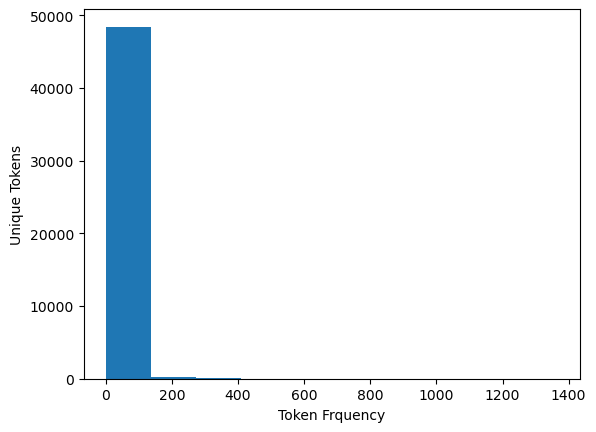

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt 



plt.hist(token_count.values(), bins = 10)
plt.xlabel("Token Frquency")
plt.ylabel('Unique Tokens')
#Q1: I noticed that the more frequent a token occured, the less uniqueness its value was in comparison. 




**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

In [ ]:
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("/Users/jieiota/Documents/Year 3 Semester 1/DS 3001/A05-pca/data/Phishing_clean.parquet")


X = df.drop(columns=['Email Type'])
Y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print( X_train,'\n', X_test)
print( y_train,'\n', y_test)


classification_scaler = MinMaxScaler()
X_train_scaled = classification_scaler.fit_transform(X_train)
X_test_scaled = classification_scaler.transform(X_test)

eval_ks = np.arange(1, 51)
eval_valid = []
for eval_k in eval_ks:
    model = KNeighborsClassifier(n_neighbors= int(eval_k))
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    eval_valid.append(np.mean(predictions == y_test))

best_k = int(eval_ks[np.argmax(eval_valid)])
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)






       new  date  get  please  enron  like  2002  would  one  message  ...  \
5025     0     0    0       0      0     0     0      0    0        0  ...   
3800     0     0    0       0      0     1     0      0    0        0  ...   
4084     0     1    0       0      0     0     0      0    0        0  ...   
1475     0     0    0       0      0     0     0      0    0        0  ...   
3608     0     0    0       0      0     0     0      0    0        0  ...   
...    ...   ...  ...     ...    ...   ...   ...    ...  ...      ...  ...   
11284    0     0    0       0      0     0     0      0    0        0  ...   
11964    0     1    0       0      0     0     0      0    0        0  ...   
5390     0     0    0       0      0     0     0      0    1        1  ...   
860      0     0    0       0      0     0     0      0    0        0  ...   
15795    0     0    0       0      0     0     0      0    0        0  ...   

       ï¿½ï¿½  safety  yap  ypil  maintain  procedures  tip  el

KNeighborsClassifier(n_neighbors=2)

In [ ]:
#Q2.2:
from sklearn.linear_model import LinearRegression

sk_fit = LinearRegression().fit(X_train, y_train)

print("R-squared:", round(sk_fit.score(X_train, y_train), 4))
print("R-squared:", round(sk_fit.score(X_test, y_test), 4))

#Q2.3: The words that have the largest coefficients in absolute value are intervention, localized, thermal, and crawler.
coefficients = pd.Series(sk_fit.coef_, index=X_train.columns).round(4)

print("coefficients:", coefficients.abs().sort_values(ascending=False).head(10))

R-squared: 0.767
R-squared: 0.6659
coefficients: intervention         1.2593
localized            0.8244
thermal              0.7470
crawler              0.6962
background-image:    0.6229
helvetica,           0.5986
aging                0.5950
form.                0.5769
a:active             0.5745
gray;                0.5745
dtype: float64


**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

Rows and score columns: (18634, 2)
Sklearn: [0.011 0.009]


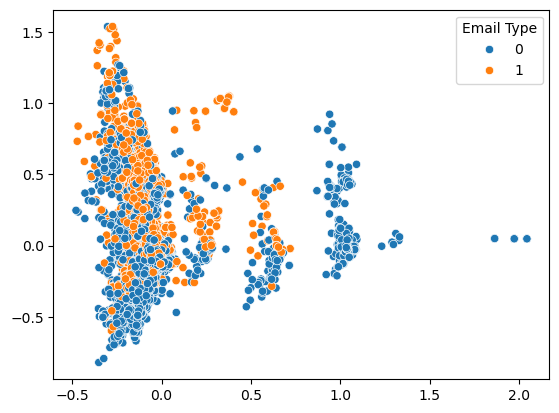

In [ ]:
#Q3: The two principal components have heavy overlap at the beginnning but as it continues further down the x axis, 
# the blue points seem to overtake

from sklearn.decomposition import PCA
pca_house = PCA(n_components=2).fit(X)
X_pca_sklearn = pca_house.transform(X)

sns.scatterplot(x = X_pca_sklearn[:, 0], y = X_pca_sklearn[:,1], hue = Y)
print("Rows and score columns:", X_pca_sklearn.shape)
print("Sklearn:", pca_house.explained_variance_ratio_.round(3))


**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

In [40]:
#Q4
pca_house = PCA(n_components=2610).fit(X_train)
X_pca_sklearn_train = pca_house.transform(X_train)
X_pca_sklearn_test = pca_house.transform(X_test)

sk_fit = LinearRegression().fit(X_pca_sklearn_train, y_train)

print("R-squared:", round(sk_fit.score(X_pca_sklearn_train, y_train), 4))
print("R-squared:", round(sk_fit.score(X_pca_sklearn_test, y_test), 4))


R-squared: 0.7662
R-squared: 0.6683


**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Jiei Ota

**Date:** 10/21/26

In [ ]:
# Your Phase 1 solution to the problem goes here.
import seaborn as sns
import matplotlib.pyplot as plt 
#Q1: I noticed that the more frequent a token occured, the less uniqueness its value was in comparison. 

plt.hist(token_count.values(), bins = 10)
plt.xlabel("Token Frquency")
plt.ylabel('Unique Tokens')


In [ ]:
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.linear_model import LinearRegression
#Q2.1
df = pd.read_parquet("/Users/jieiota/Documents/Year 3 Semester 1/DS 3001/A05-pca/data/Phishing_clean.parquet")

X = df.drop(columns=['Email Type'])
Y = df['Email Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print( X_train,'\n', X_test)
print( y_train,'\n', y_test)

classification_scaler = MinMaxScaler()
X_train_scaled = classification_scaler.fit_transform(X_train)
X_test_scaled = classification_scaler.transform(X_test)

eval_ks = np.arange(1, 51)
eval_valid = []
for eval_k in eval_ks:
    model = KNeighborsClassifier(n_neighbors= int(eval_k))
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    eval_valid.append(np.mean(predictions == y_test))

best_k = int(eval_ks[np.argmax(eval_valid)])
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled, y_train)

In [ ]:
#Q2.2:
from sklearn.linear_model import LinearRegression

sk_fit = LinearRegression().fit(X_train, y_train)

print("R-squared:", round(sk_fit.score(X_train, y_train), 4))
print("R-squared:", round(sk_fit.score(X_test, y_test), 4))

#Q2.3: The words that have the largest coefficients in absolute value are intervention, localized, thermal, and crawler.
coefficients = pd.Series(sk_fit.coef_, index=X_train.columns).round(4)

print("coefficients:", coefficients.abs().sort_values(ascending=False).head(10))

In [ ]:
#Q3: The two principal components have heavy overlap at the beginnning but as it continues further down the x axis, 
# the blue points seem to overtake

from sklearn.decomposition import PCA
pca_house = PCA(n_components=2).fit(X)
X_pca_sklearn = pca_house.transform(X)

sns.scatterplot(x = X_pca_sklearn[:, 0], y = X_pca_sklearn[:,1], hue = Y)
print("Rows and score columns:", X_pca_sklearn.shape)
print("Sklearn:", pca_house.explained_variance_ratio_.round(3))

In [ ]:
#Q4
pca_house = PCA(n_components=2610).fit(X_train)
X_pca_sklearn_train = pca_house.transform(X_train)
X_pca_sklearn_test = pca_house.transform(X_test)

sk_fit = LinearRegression().fit(X_pca_sklearn_train, y_train)

print("R-squared:", round(sk_fit.score(X_pca_sklearn_train, y_train), 4))
print("R-squared:", round(sk_fit.score(X_pca_sklearn_test, y_test), 4))

#Q5: The advantage in using principal components is that it reduces the amount of variables needed which 
# ultimately makes the regesision process easier as it has less to analyze.  

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [29]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]